# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [1]:
# Escribe aquí tu código para descargar los datos de tus 3 activos elegidos

import yfinance as yf
import pandas as pd

activos = ["ADBE", "WFC", "MCD"]

datos = yf.download(
    activos,
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=True
)

datos.head()

[*********************100%***********************]  3 of 3 completed


Price            Close                               High              \
Ticker            ADBE         MCD        WFC        ADBE         MCD   
Date                                                                    
2024-01-02  580.070007  277.953186  46.275784  590.440002  278.177755   
2024-01-03  571.789978  275.473450  45.666031  577.299988  278.842102   
2024-01-04  567.049988  272.993744  46.228878  572.909973  278.168403   
2024-01-05  564.599976  270.420502  46.829258  569.520020  271.674395   
2024-01-08  580.549988  273.143524  46.829258  581.510010  273.237104   

Price                         Low                               Open  \
Ticker            WFC        ADBE         MCD        WFC        ADBE   
Date                                                                   
2024-01-02  46.679157  576.760010  276.091038  45.797358  589.510010   
2024-01-03  46.050646  570.190002  275.342432  45.328319  574.580017   
2024-01-04  46.772970  566.659973  272.226456  45.750456  570.989990   
2024-01-05  47.345208  563.340027  268.745541  46.238266  563.500000   
2024-01-08  46.894927  567.869995  269.044963  46.106935  567.869995   

Price                               Volume                     
Ticker             MCD        WFC     ADBE      MCD       WFC  
Date                                                           
2024-01-02  276.091038  46.013117  2840200  4458400  14916000  
2024-01-03  277.915726  46.050646  2478000  3114800  21653600  
2024-01-04  276.343721  45.797359  2092100  4615400  15917500  
2024-01-05  270.626366  46.341456  1923200  3407300  15074800  
2024-01-08  269.971369  46.322694  2830000  3097000  15119700

Se han descargado los datos históricos de tres activos financieros: Adobe (ADBE), Wells Fargo (WFC) y McDonald's (MCD), abarcando el periodo del 1 de enero de 2024 al 1 de enero de 2026. Al visualizar las primeras cinco filas, podemos confirmar la estructura de los datos y asegurarnos de que hay registros para los activos seleccionados.

## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

In [2]:
# 1. Extraer los precios de cierre

precios_cierre = datos["Close"]
precios_cierre.head()


Ticker,ADBE,MCD,WFC
Date,,,
2024-01-02,580.070007,277.953186,46.275784
2024-01-03,571.789978,275.473450,45.666031
2024-01-04,567.049988,272.993744,46.228878
2024-01-05,564.599976,270.420502,46.829258
2024-01-08,580.549988,273.143524,46.829258


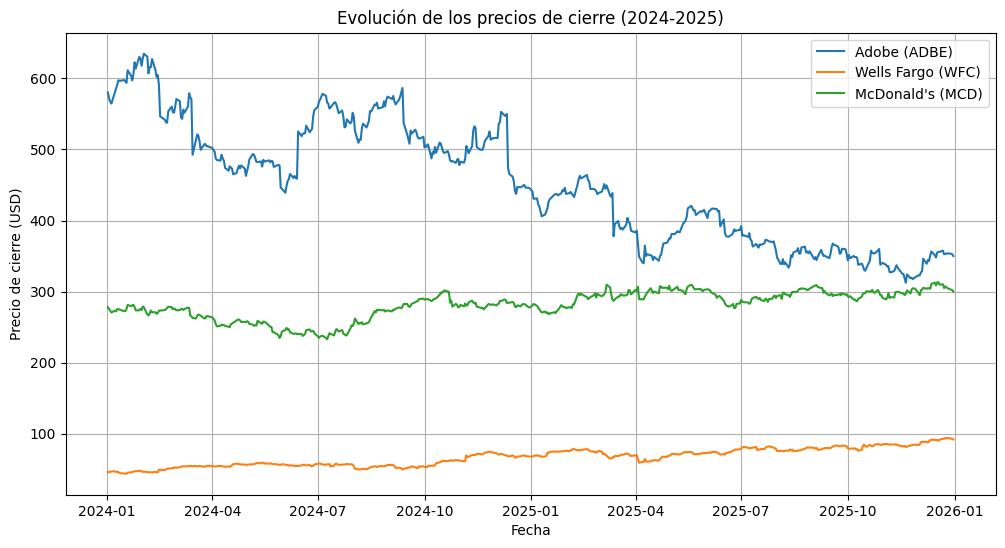

In [3]:
# 2. Graficar precios originales

import matplotlib.pyplot as plt

# Graficar los precios de cierre originales
plt.figure(figsize=(12, 6))

plt.plot(precios_cierre.index, precios_cierre["ADBE"], label="Adobe (ADBE)")
plt.plot(precios_cierre.index, precios_cierre["WFC"], label="Wells Fargo (WFC)")
plt.plot(precios_cierre.index, precios_cierre["MCD"], label="McDonald's (MCD)")

plt.title("Evolución de los precios de cierre (2024-2025)")
plt.xlabel("Fecha")
plt.ylabel("Precio de cierre (USD)")
plt.legend()
plt.grid(True)
plt.show()

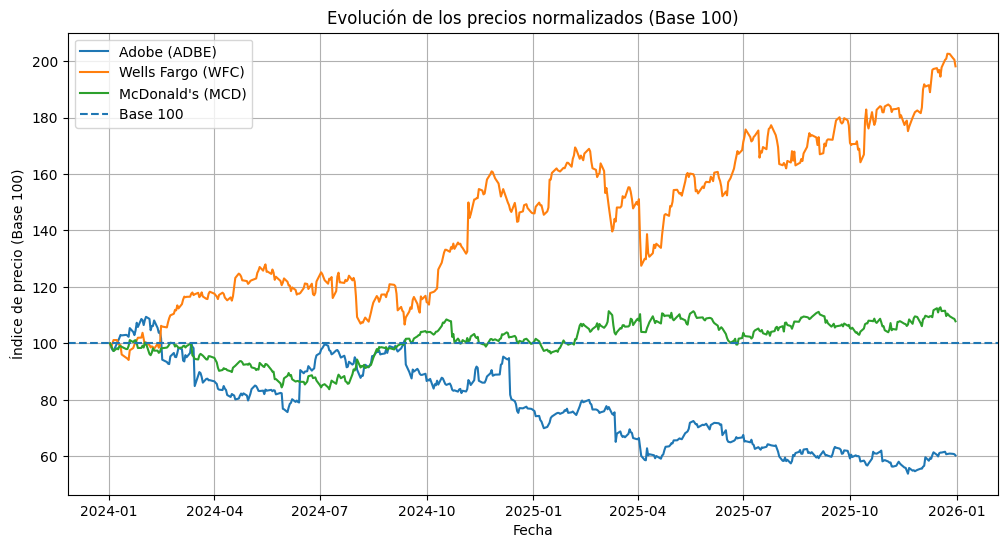

In [4]:
# 3. Normalizar y graficar en base 100

precios_normalizados = precios_cierre.div(
    precios_cierre.iloc[0]
) * 100

# Graficar las series normalizadas
plt.figure(figsize=(12, 6))

plt.plot(precios_normalizados.index, precios_normalizados["ADBE"],
         label="Adobe (ADBE)")
plt.plot(precios_normalizados.index, precios_normalizados["WFC"],
         label="Wells Fargo (WFC)")
plt.plot(precios_normalizados.index, precios_normalizados["MCD"],
         label="McDonald's (MCD)")

plt.axhline(y=100, linestyle="--", label="Base 100")

plt.title("Evolución de los precios normalizados (Base 100)")
plt.xlabel("Fecha")
plt.ylabel("Índice de precio (Base 100)")
plt.legend()
plt.grid(True)
plt.show()


# Pregunta de interpretación #1:

El gráfico normalizado es una mejor opción porque nos permite comparar el rendimiento porcentual de los activos desde una base común de 100, sin tener en cuenta sus precios iniciales. Por ejemplo, vemos que Wells Fargo creció alrededor de un 100 %, McDonald's subió un 10 % y Adobe, por otro lado, cayó cerca de un 40 %. En contraste, el gráfico de precios reales presenta valores en dólares, lo que complica la comparación de su rendimiento.

## 🔄 Paso 3: Cálculo y Distribución de Rendimientos

1. Calcula los rendimientos diarios de los activos y elimina los valores nulos (`NaN`).
2. Genera un **histograma* para el activo que consideres que haya sido el más volátil.
3. Diseña un **Boxplot** comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

### 💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:
- ¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
- ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

In [5]:
# 1. Calcular rendimientos
rendimientos = precios_cierre.pct_change()

# Eliminar valores nulos
rendimientos = rendimientos.dropna()

# Mostrar las primeras cinco filas
rendimientos.head()


Ticker,ADBE,MCD,WFC
Date,,,
2024-01-03,-0.014274,-0.008921,-0.013176
2024-01-04,-0.008290,-0.009002,0.012325
2024-01-05,-0.004321,-0.009426,0.012987
2024-01-08,0.028250,0.010070,0.000000
2024-01-09,0.009732,-0.003529,-0.012620


Volatilidad de los activos:
Ticker
ADBE    0.021241
MCD     0.011449
WFC     0.018218
dtype: float64

Activo más volátil: ADBE


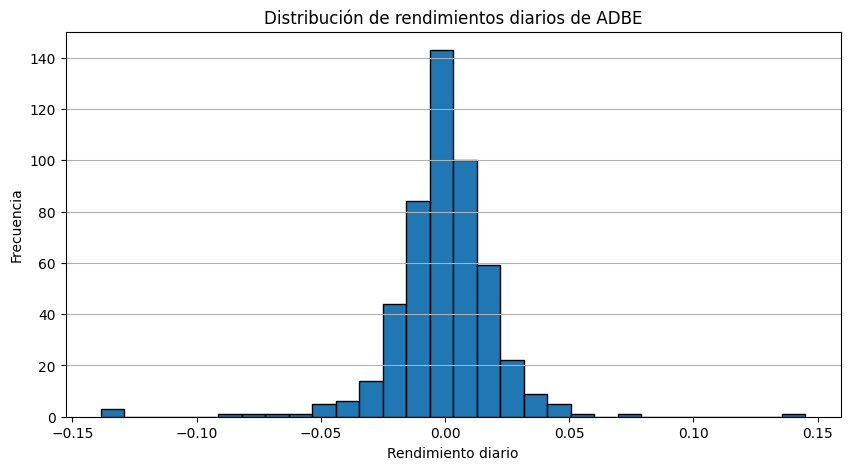

In [6]:
# 2. Histograma con el activo más volátil

volatilidad = rendimientos.std()

print("Volatilidad de los activos:")
print(volatilidad)

activo_mas_volatil = volatilidad.idxmax()

print("\nActivo más volátil:", activo_mas_volatil)

# Grafica del histograma
plt.figure(figsize=(10, 5))

plt.hist(rendimientos[activo_mas_volatil], bins=30, edgecolor="black")

plt.title(f"Distribución de rendimientos diarios de {activo_mas_volatil}")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")
plt.grid(axis="y")
plt.show()

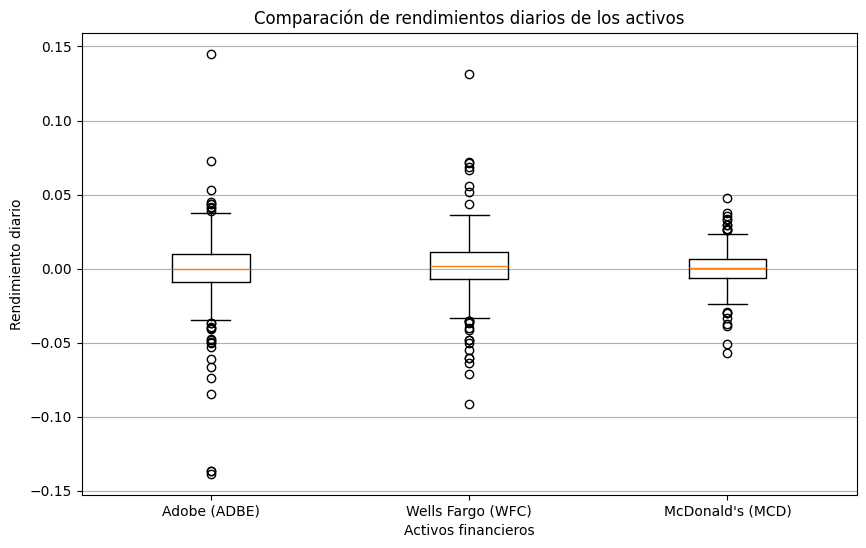

In [7]:
# 3. Boxplot comparativo de rendimientos

plt.figure(figsize=(10, 6))

plt.boxplot(
    [rendimientos["ADBE"], rendimientos["WFC"], rendimientos["MCD"]],
    tick_labels=["Adobe (ADBE)", "Wells Fargo (WFC)", "McDonald's (MCD)"]
)

plt.title("Comparación de rendimientos diarios de los activos")
plt.xlabel("Activos financieros")
plt.ylabel("Rendimiento diario")
plt.grid(axis="y")
plt.show()

# Pregunta de interpretación #2:

1. ¿Qué activo presenta la mayor dispersión y qué te dice sobre su riesgo?
El activo con mayor dispersión es Adobe (ADBE) se nota con una caja y líneas más amplios en la segunda gráfica, además de ser confirmado como el más volátil en los datos superiores).

¿Qué significa para el riesgo?: nos da a entender que es una opción más riesgosa, ya que sus ganancias y pérdidas diarias cambian con mucha más rapidez en comparación con las demás. McDonald's (MCD), en cambio, muestra el comportamiento más estable.

2. ¿Identificas valores atípicos (outliers) y qué representan?
Sí, se identifican claramente varios círculos fuera de las líneas principales en los tres activos, especialmente en Adobe y Wells Fargo, con saltos muy altos o caídas profundas.

¿Qué representan?: Representan días extraordinarios o de sorpresas extremas en la economía, como momentos de crisis financieras, anuncios inesperados de ganancias, cambios drásticos en las tasas de interés o eventos mundiales imprevistos. que causaron movimientos en las bolsas muy por fuera de lo normal.

## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

In [8]:
# 1. Calcular matriz de correlación

matriz_correlacion = rendimientos.corr(method="pearson")
matriz_correlacion


Ticker,ADBE,MCD,WFC
Ticker,,,
ADBE,1.000000,0.160489,0.223281
MCD,0.160489,1.000000,0.095744
WFC,0.223281,0.095744,1.000000


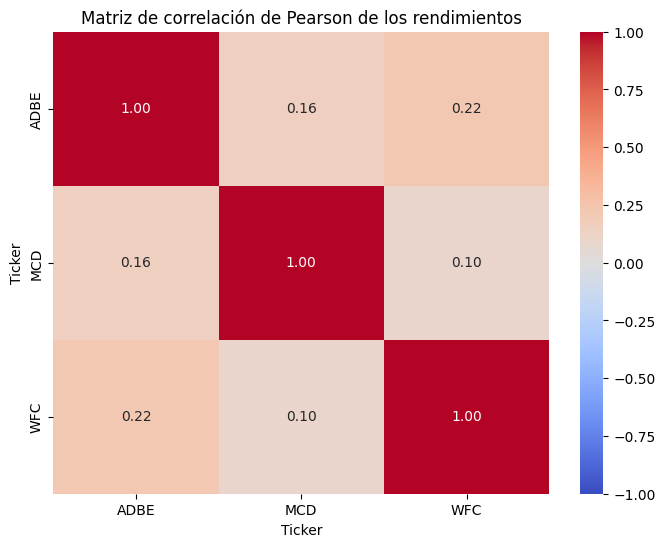

In [9]:
# 2. Dibujar el Heatmap utilizando Seaborn
import seaborn as sns
import matplotlib.pyplot as plt

# Graficar el mapa de calor
plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Matriz de correlación de Pearson de los rendimientos")
plt.show()

1. **¿Existe alguna correlación fuerte entre alguno de los activos?**
No, ninguna. Todos los valores son muy bajos entre 0.10 y 0.22, alejados del 1 o del -1.   
**¿Qué te dice esto?:**
que los activos se comportan de manera muy independiente entre sí.

Si tuviera que elegir un par de activos para crear un portafolio diversificado, optaría por McDonald's (MCD) y Wells Fargo (WFC).

**¿porque?** Tienen la relación más baja entre ellos, con un 0.10, que es el número más cercano a cero en la tabla. Esto significa que son bastante independientes el uno del otro, Si uno de ellos enfrenta dificultades, es muy probable que el otro no se vea afectado de la misma manera, lo que ayuda a proteger mejor tu inversión.

## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

In [11]:
# Generar resumen de estadísticas descriptivas (Media, Mediana, Desviación estándar, Mínimo y Máximo)

resumen_estadistico = pd.DataFrame({
    "Media": rendimientos.mean(),
    "Mediana": rendimientos.median(),
    "Desviación Estándar": rendimientos.std(),
    "Mínimo": rendimientos.min(),
    "Máximo": rendimientos.max()
})

resumen_estadistico



,Media,Mediana,Desviación Estándar,Mínimo,Máximo
Ticker,,,,,
ADBE,-0.000778,-0.000325,0.021241,-0.138532,0.145115
MCD,0.000216,0.000221,0.011449,-0.057059,0.047978
WFC,0.001531,0.001684,0.018218,-0.091198,0.131107


# **conclusión final**

Wells Fargo fue el activo con mayor crecimiento promedio, mientras que Adobe presentó mayores cambios en sus precios y pérdidas promedio. McDonald's tuvo menos variaciones, por lo que podría ser una opción para quien prefiera asumir menos riesgo.